# Statistics of CHAMP density caculations




In [1]:
%load_ext autoreload
%autoreload 2

In [25]:
import pandas as pd
import numpy as np
import glob

import matplotlib.pyplot as plt

from contigo.constellation import Constellation
from contigo.edr_efd import EDRDensity

# Ephemeris
from contigo.ephemeris.orekit_ephem import OrekitEphem
from contigo.solar_system_ephem import SolarSystemEnvironment

# Forces and acceleration
from contigo.forces.third_body_acc import ThirdBodyEnv
from contigo.forces.grav_pot import EarthPotential
from contigo.forces.srp_orekit import SRPOrekitCB

# HASDM Helper
from contigo.contigo_utils.hasdm_utils import read_hasdm, extract_along_track_density

In [3]:
fn = r"D:\data\SatDensities\CHAMP\CHAMP_2010.hdf"

ch_orb = pd.read_hdf(fn)

ch_orb[['x','y','z']] = ch_orb[['x','y','z']]*1000.0
ch_orb[['vx','vy','vz']] = ch_orb[['vx','vy','vz']]*1000.0
ch_orb['v'] = np.linalg.norm(ch_orb[['vx','vy','vz']].to_numpy(),axis=1)
ch_orb['r'] = np.linalg.norm(ch_orb[['x','y','z']].to_numpy(),axis=1)
ch_orb['DateTime'] = ch_orb['time']
ch_orb['cd'] = 3.5 
ch_orb['drag_area'] = 0.80
ch_orb['cr'] = 1.28
ch_orb['srp_area'] = 2.25
ch_orb['mass'] = 500
ch_orb['id'] = 'CHAMP'

print('Mean altitude (km):',(ch_orb['r'].mean()-6371*1000.)/1000.0)

Mean altitude (km): 290.3078637175728


In [4]:
hdf_sc = Constellation(state=ch_orb[['x','y','z','vx','vy','vz']].to_numpy(), 
                        time=ch_orb['time'].to_numpy(), 
                        cd=ch_orb['cd'].to_numpy(),
                        drag_area=ch_orb['drag_area'].to_numpy(),
                        sc_mass=ch_orb['mass'].to_numpy(),
                        cr=ch_orb['cr'].to_numpy(),
                        srp_area=ch_orb['srp_area'].to_numpy(), 
                        sc_id_input=ch_orb['id'], 
                        tscale_input='GPS')

hdf_sc

Constellation(n_spacecraft=1, ids=['CHAMP'])

In [ ]:
# setup the ephemeris provider we want
# and the solar system environement 
# which defines the tolerance for ephemeris cacheing and the bodies we want
# in our solar system
ephem = OrekitEphem( )

env = SolarSystemEnvironment(bodies=['SUN','MOON'], tolerance=0.01, provider=ephem, 
                            ephem_time=hdf_sc.sspice_et, 
                            gps_time=hdf_sc.sspice_gps,
                            utc_time=hdf_sc.sc_utc)

# this is a big lmax but this is what 
# we use in the orekit derivation and
# is what we need here to for a comparison
ep = EarthPotential(lmax=100) 
tba_env = ThirdBodyEnv( )
srp = SRPOrekitCB( )

# create the EDRDensity object and calculate
# EDR and the denom
edr = EDRDensity(constellation=hdf_sc,
                 solarsys_env=env, 
                 force_models=[tba_env,srp],
                 potential_model=ep)

acc_con = edr.compute_edr()
den_con = edr.compute_denom()
efd_con = edr.compute_den()

INFO:Loading potential file D:\GitHub\contigo_edr\contigo\data\EIGEN-2.gfc
INFO:Loading potential coeffecients from current state which used EIGEN-2.gfc.


<Axes: xlabel='DateTime'>

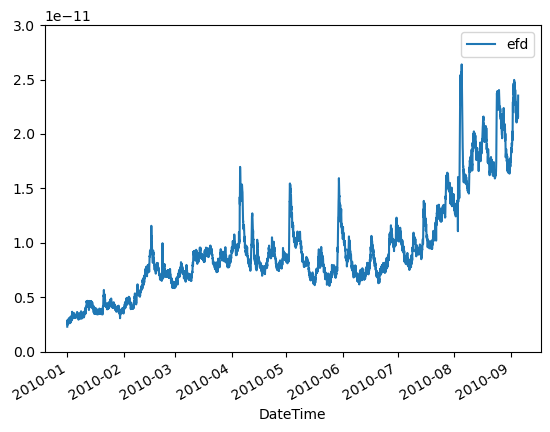

In [6]:
efd_con['CHAMP'].plot(x='DateTime',y='efd',ylim=[0,30e-12])

# Model Desnities


In [7]:
fn_mod = r"D:\data\SatDensities\alt_model\CH_alt_oos_old.hdf"
ch_mod = pd.read_hdf(fn_mod)[['DateTime','den_obs', 'jb08', 'msis', 'msis_st',
                              'alt','lat','lon']]
ch_mod['den_obs'] = ch_mod['den_obs']*1e-12

gd = (ch_mod['DateTime'] >= ch_orb['DateTime'].min()) & (ch_mod['DateTime'] <= ch_orb['DateTime'].max())
ch_mod = ch_mod[gd].sort_values('DateTime').reset_index(drop=True)

ch_mod = pd.merge_asof(ch_mod, ch_orb[['DateTime','x','y','z','vx','vy','vz','v','r']], 
                       on='DateTime', direction='nearest', tolerance=pd.Timedelta('2.5m'))


In [8]:
hasdm_den = read_hasdm(sorted(glob.glob('D:/data/HASDM/2010*.zip')))
ch_hasdm = extract_along_track_density(
    hasdm_den,
    sat_times = ch_mod["DateTime"].values.astype("datetime64[ns]"),
    sat_lat   = ch_mod["lat"].values,
    sat_lon   = ch_mod["lon"].values,
    sat_alt   = ch_mod["alt"].values*1000.0,
    max_dt    = pd.Timedelta(hours=1, minutes=30),
)

d:\GitHub\contigo_edr\contigo\contigo_utils\hasdm_utils.py:657: UserWarning: 953 HASDM epoch(s) had no satellite data within 0 days 01:30:00; those entries will have NaN density.
  matches = match_satellite_to_hasdm(


In [9]:
ch_hasdm

,hasdm_time,sat_time,sat_lat,sat_lon,sat_alt,hasdm_lat,hasdm_lon,hasdm_alt,rho,dt_sec,i_time,i_lat,i_lon,i_alt
0,2010-01-01 00:00:00,2009-12-31 23:10:00,-22.933987,-33.948761,313735.125000,-20.0,330.0,325000.0,2.170000e-12,3000.0,0,7,22,6
1,2010-01-01 03:00:00,2010-01-01 03:00:00,35.889809,89.160393,307828.468750,40.0,90.0,300000.0,5.516000e-12,0.0,1,13,6,5
2,2010-01-01 06:00:00,2010-01-01 06:00:00,30.563107,43.615425,306783.812500,30.0,45.0,300000.0,5.145000e-12,0.0,2,12,3,5
3,2010-01-01 09:00:00,2010-01-01 09:00:00,25.239773,-1.888074,306181.593750,30.0,0.0,300000.0,5.531000e-12,0.0,3,12,0,5
4,2010-01-01 12:00:00,2010-01-01 12:00:00,19.920025,-47.363308,306039.125000,20.0,315.0,300000.0,5.981000e-12,0.0,4,11,21,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2915,2010-12-31 09:00:00,2010-09-04 14:30:00,-25.585890,110.813362,257199.765625,NaN,NaN,NaN,NaN,10175400.0,2915,-1,-1,-1
2916,2010-12-31 12:00:00,2010-09-04 14:30:00,-25.585890,110.813362,257199.765625,NaN,NaN,NaN,NaN,10186200.0,2916,-1,-1,-1
2917,2010-12-31 15:00:00,2010-09-04 14:30:00,-25.585890,110.813362,257199.765625,NaN,NaN,NaN,NaN,10197000.0,2917,-1,-1,-1
2918,2010-12-31 18:00:00,2010-09-04 14:30:00,-25.585890,110.813362,257199.765625,NaN,NaN,NaN,NaN,10207800.0,2918,-1,-1,-1


In [10]:
ch_mod = pd.merge_asof(ch_mod, ch_hasdm[['sat_time','rho']], 
                        left_on='DateTime', right_on='sat_time',
                        direction='nearest', tolerance=pd.Timedelta('5m')) 

In [11]:
ch_mod['rho'] = ch_mod.set_index('DateTime')['rho'].interpolate(method='time').values

In [12]:
ch_mod

,DateTime,den_obs,jb08,msis,msis_st,alt,lat,lon,x,y,z,vx,vy,vz,v,r,sat_time,rho
0,2009-12-31 22:00:00,2.594564e-12,3.172732e-12,4.121338e-12,4.010329e-12,333.401855,-75.148018,151.963120,-1522966.804,811033.306,-6465284.589,-7075.992555,2268.602954,1952.564653,7683.016252,6.691570e+06,NaT,NaN
1,2009-12-31 22:05:00,2.748471e-12,3.509019e-12,4.871548e-12,4.788784e-12,327.378876,-55.586502,157.153625,-3499987.171,1474593.538,-5508641.818,-5974.338082,2103.048209,4362.268824,7690.573228,6.690999e+06,NaT,NaN
2,2009-12-31 22:10:00,3.429842e-12,4.133651e-12,5.525354e-12,5.468092e-12,318.932861,-35.826107,157.941620,-5038007.142,2041459.804,-3899244.978,-4179.836640,1624.995402,6260.627763,7701.110594,6.689782e+06,NaT,NaN
3,2009-12-31 22:15:00,3.578051e-12,4.802534e-12,5.983434e-12,5.937840e-12,311.143066,-15.946307,157.893143,-5960461.912,2421122.590,-1826498.232,-1913.024441,863.817991,7419.517643,7710.712424,6.687678e+06,NaT,NaN
4,2009-12-31 22:20:00,3.284087e-12,5.119743e-12,6.175427e-12,6.135255e-12,306.591156,4.004497,157.621857,-6166315.135,2538819.866,463851.887,548.060069,-105.341156,7695.887733,7716.097109,6.684625e+06,NaT,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69810,2010-09-04 14:10:00,2.259071e-11,2.605413e-11,2.611999e-11,2.514713e-11,253.311661,55.124985,110.511879,-1331536.081,3559104.154,5417169.067,-2577.743758,5801.764296,-4432.763991,7743.037416,6.617094e+06,NaT,2.826971e-11
69811,2010-09-04 14:15:00,3.037511e-11,2.786507e-11,2.800793e-11,2.717906e-11,249.586166,35.018372,111.299400,-1973731.281,5062514.341,3782758.737,-1671.870402,4111.136181,-6350.963309,7747.988531,6.620720e+06,NaT,2.823314e-11
69812,2010-09-04 14:20:00,2.947857e-11,2.841842e-11,2.635654e-11,2.566469e-11,248.057098,14.823243,111.256493,-2322826.079,5971133.030,1684663.437,-647.861257,1876.530513,-7491.679033,7750.248107,6.624805e+06,NaT,2.819657e-11
69813,2010-09-04 14:25:00,2.444602e-11,2.583880e-11,2.337686e-11,2.272569e-11,250.583496,-5.401584,110.999947,-2365034.013,6161141.064,-619998.515,350.817650,-629.616703,-7713.812430,7747.411982,6.628533e+06,2010-09-04 14:30:00,2.816000e-11


In [13]:
from scipy.integrate import simpson

step = pd.Timedelta(minutes=90)
s = ch_mod['DateTime'].min()
e = s+step

tol_efd = []
jb_efd = []
msis_efd = []
msis_st_efd = []
hasdm_efd = []
tol_dt = []

while e < ch_mod['DateTime'].max():
    gd_ind = (ch_mod['DateTime'] >= s) & (ch_mod['DateTime'] < e)

    if gd_ind.sum() < 10:
        s = s+step
        e = e+step
        continue

    v = ch_mod.loc[gd_ind,'v'].to_numpy()
    dt = ch_mod.loc[gd_ind,'den_obs'].to_numpy()
    dj = ch_mod.loc[gd_ind,'jb08'].to_numpy()
    dm = ch_mod.loc[gd_ind,'msis'].to_numpy()
    dm_st = ch_mod.loc[gd_ind,'msis_st'].to_numpy()
    dh = ch_mod.loc[gd_ind,'rho'].to_numpy()


    x = ch_mod.loc[gd_ind,'DateTime']
    x = (x-x.min()).dt.total_seconds().to_numpy()
    
    nume_t = simpson(dt*v**3,x)
    nume_dj = simpson(dj*v**3,x)
    nume_dm = simpson(dm*v**3,x)
    nume_dm_st = simpson(dm_st*v**3,x)
    nume_h = simpson(dh*v**3,x)
    deno = simpson(v**3,x)

    tol_efd.append(nume_t/deno)
    jb_efd.append(nume_dj/deno)
    msis_efd.append(nume_dm/deno)
    msis_st_efd.append(nume_dm_st/deno)
    hasdm_efd.append(nume_h/deno)
    tol_dt.append(s)

    s = s+step
    e = e+step

tol_efd = pd.DataFrame({'efd_tol':tol_efd, 'efd_jb':jb_efd, 
                        'efd_msis':msis_efd, 'efd_msis_st':msis_st_efd,
                        'hasdm_efd':hasdm_efd,
                        'DateTime':tol_dt})


<Axes: xlabel='DateTime'>

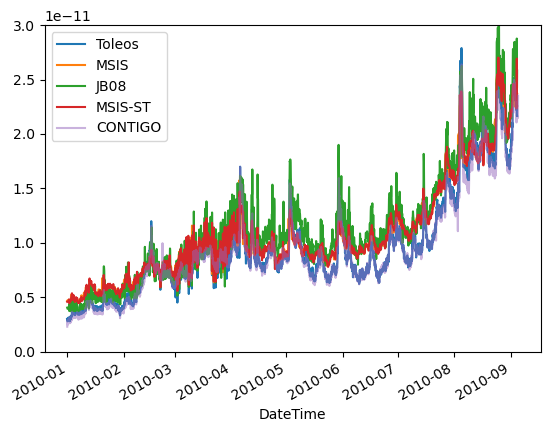

In [14]:
ax = tol_efd.plot(x='DateTime',y=['efd_tol','efd_msis', 'efd_jb', 'efd_msis_st'],ylim=[0,30e-12], label=['Toleos','MSIS', 'JB08','MSIS-ST'])
efd_con['CHAMP'].plot(x='DateTime',y='efd',label='CONTIGO', ax=ax, alpha=0.5)

In [15]:
con_efd = efd_con['CHAMP'].copy()
con_efd['DateTime'] = pd.to_datetime(con_efd['DateTime'].dt.tz_localize(None),unit='ns').astype('datetime64[ns]')


In [16]:
comb_dat = pd.merge_asof(tol_efd, con_efd, 
                        left_on='DateTime', right_on='DateTime',
                        direction='nearest', tolerance=pd.Timedelta('45m')) 

In [17]:
comb_dat = comb_dat.dropna()

In [18]:
comb_dat

,efd_tol,efd_jb,efd_msis,efd_msis_st,hasdm_efd,DateTime,efd
1,3.031228e-12,3.933094e-12,4.697293e-12,4.585322e-12,4.437906e-12,2010-01-01 01:00:00,2.676431e-12
2,2.775539e-12,3.929326e-12,4.697978e-12,4.586862e-12,5.430331e-12,2010-01-01 02:30:00,2.769489e-12
3,2.951225e-12,3.930967e-12,4.707242e-12,4.595364e-12,5.303190e-12,2010-01-01 04:00:00,2.449343e-12
4,2.955461e-12,3.936811e-12,4.723246e-12,4.608949e-12,5.186147e-12,2010-01-01 05:30:00,2.876316e-12
5,2.872636e-12,3.937945e-12,4.733520e-12,4.615675e-12,5.366440e-12,2010-01-01 07:00:00,2.559004e-12
...,...,...,...,...,...,...,...
3894,2.238875e-11,2.607593e-11,2.325961e-11,2.260572e-11,1.614968e-11,2010-09-04 02:30:00,2.153922e-11
3895,2.623682e-11,2.876757e-11,2.790240e-11,2.692225e-11,1.666937e-11,2010-09-04 05:30:00,2.118234e-11
3896,2.164269e-11,2.410947e-11,2.365174e-11,2.270220e-11,1.636970e-11,2010-09-04 07:00:00,2.124000e-11
3897,2.169584e-11,2.428916e-11,2.368824e-11,2.262873e-11,1.749747e-11,2010-09-04 08:30:00,2.195350e-11


In [19]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import median_absolute_error
# train and test data
score = ['MNAE','MNPE','MDAE']
sc_ag = [mean_absolute_error,mean_absolute_percentage_error,median_absolute_error]
sc_d = {}

y_tr = 'efd_tol'
y_mod = ['efd','efd_jb','efd_msis','efd_msis_st','hasdm_efd']

for sc, ag in zip(score, sc_ag):
    for y in y_mod:     
        val_sc = ag(comb_dat[y_tr],comb_dat[y])
        if sc in sc_d:
            sc_d[sc].append(val_sc) 
        else:
            sc_d[sc] = [val_sc]

In [20]:
pd.DataFrame(sc_d, index=y_mod)

,MNAE,MNPE,MDAE
efd,3.535847e-13,0.037364,2.509840e-13
efd_jb,1.785789e-12,0.197506,1.700366e-12
efd_msis,1.391876e-12,0.178351,1.303809e-12
efd_msis_st,1.326027e-12,0.169969,1.283026e-12
hasdm_efd,4.032554e-12,0.407273,2.831915e-12


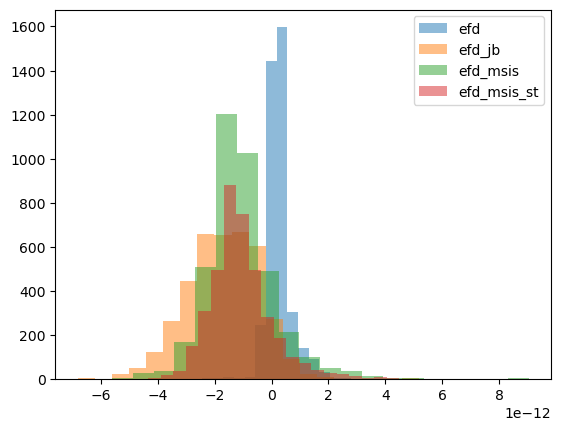

In [29]:
fig, ax = plt.subplots()

y_tr = 'efd_tol'
y_mod = ['efd','efd_jb','efd_msis','efd_msis_st']

for y in y_mod:
    ax.hist(comb_dat[y_tr]-comb_dat[y], bins=20, alpha=0.5, label=y)

ax.legend()
